# Old (hand-collected) vs new (data.iep.ru) datasets

* **old** = what `FeaturesService` used before: excel files in `data/` + chained indices converted by `_convert_indeces_to_basics`
* **new** = `data_iep` output (`data/iep/*.parquet`), latest IEP release (vintage) of every series

The sets cover different periods, so everything is compared on the overlap.
Levels of chained indices depend on the base period, so the main metric is the
**y/y growth** (`log x_t - log x_{t-12}` monthly, `t-4` quarterly), which is exactly what
the models consume as `*_log_d12` / `*_log_d4` features.

In [23]:
import polars as pl
pl.read_csv(r'C:\Users\pc\Dropbox\ПК\Desktop\russia_forecasting\results\metrics_history.csv')

model,train_start,var_set,features_type,availability,target,horizon,n,rmse,mae,bias,rmse_naive,mae_naive,rel_rmse_naive,rel_mae_naive,run_id,last_known_quarter
str,i64,str,str,i64,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,str,str
"""dfm""",2000,"""all""","""classic""",1,"""cons""",1,12,0.015735,0.012431,-0.012431,0.012395,0.010354,1.269457,1.200509,"""2026-10-22""","""2026-04-01"""
"""dfm""",2000,"""all""","""classic""",1,"""cons""",2,12,0.026149,0.016495,-0.015433,0.035585,0.02431,0.734832,0.678526,"""2026-10-22""","""2026-04-01"""
"""dfm""",2000,"""all""","""classic""",1,"""cons""",3,12,0.040795,0.021861,-0.017905,0.054932,0.039047,0.74264,0.55987,"""2026-10-22""","""2026-04-01"""
"""dfm""",2000,"""all""","""classic""",1,"""cons""",4,12,0.04821,0.028033,-0.020967,0.070003,0.053345,0.688685,0.525506,"""2026-10-22""","""2026-04-01"""
"""dfm""",2000,"""all""","""classic""",1,"""cons""",5,12,0.050368,0.034254,-0.022174,0.079692,0.06434,0.632038,0.532392,"""2026-10-22""","""2026-04-01"""
"""dfm""",2000,"""all""","""classic""",1,"""cons""",6,12,0.049158,0.03686,-0.022248,0.076362,0.065955,0.643753,0.558871,"""2026-10-22""","""2026-04-01"""
"""dfm""",2000,"""all""","""classic""",1,"""cons""",7,12,0.041432,0.034508,-0.018677,0.072865,0.064477,0.568621,0.535201,"""2026-10-22""","""2026-04-01"""
"""dfm""",2000,"""all""","""classic""",1,"""cons""",8,12,0.035233,0.030118,-0.015503,0.067906,0.058187,0.518849,0.517613,"""2026-10-22""","""2026-04-01"""
"""dfm""",2000,"""all""","""classic""",1,"""gdp""",1,12,0.012189,0.008521,-0.001121,0.013978,0.010633,0.871984,0.801389,"""2026-10-22""","""2026-04-01"""


In [1]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, str(Path.cwd()))

from data_iep.pipeline import IepDataPipeline, load_iep_data
from eng_ru_names_dict import chain_indeces, yoy_indeces
from preprocess_data.prepare_data import FeaturesService

pl.Config.set_tbl_rows(100)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_fmt_str_lengths(80)

REFRESH = False  # True -> download everything from data.iep.ru again (~40 s)

OLD_COLOR, NEW_COLOR = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#a9a8a2", "axes.labelcolor": "#4b4a45",
    "xtick.color": "#6b6a64", "ytick.color": "#6b6a64", "lines.linewidth": 1.6,
})

## 1. Load both datasets

In [2]:
# --- new
if REFRESH:
    pipeline = IepDataPipeline()
    pipeline.run()
    print("failed series:", pipeline.errors or "none")
new = load_iep_data()
new_q, new_m, new_d = new["quarterly"], new["monthly"], new["daily"]
metadata = pl.read_csv("data/iep/metadata.csv")

# --- old (same steps as FeaturesService.get_features with DATA_SOURCE="manual")
fs = FeaturesService()
cbr_raw, fred_raw, old_q = fs._read_monthly_data()
giga_raw = fs._parse_giga_data()
giga = fs._convert_indeces_to_basics(giga_raw, chain_indeces, yoy_indeces)
old_m = fs._join_monhtly_data(giga, fred_raw, cbr_raw).rename({"datem": "date"})
old_q = old_q.rename({"dateq": "date"}).drop("quarter", "year")
giga_raw = giga_raw.rename({"datem": "date"})  # values exactly as typed into the excel file

for name, frame in [("old quarterly", old_q), ("new quarterly", new_q), ("old monthly", old_m), ("new monthly", new_m), ("new daily", new_d)]:
    print(f"{name:14s} {frame.width - 1:3d} vars  {frame['date'].min()} -> {frame['date'].max()}")

old quarterly    4 vars  1995-01-01 -> 2025-04-01
new quarterly    4 vars  1998-01-01 -> 2026-04-01
old monthly     63 vars  1999-01-01 -> 2025-07-01
new monthly     61 vars  1999-01-01 -> 2026-09-01
new daily        1 vars  2000-08-01 -> 2026-10-14


## 2. Which IEP release (vintage) every series came from

In [3]:
metadata.select("name", "frequency", "kind", "vintage_id", "vintage_date", "unit", "first_date", "last_date", "dimension")

name,frequency,kind,vintage_id,vintage_date,unit,first_date,last_date,dimension
str,str,str,i64,str,str,str,str,str
"""gdp_2021""","""Q""","""splice""",501351,"""2026-10-01""","""млрд рублей""","""2011-01-01""","""2026-04-01""","""млрд рублей | в ценах 2021 года | Реальный ВВП"""
"""gdp_2008""","""Q""","""splice""",501351,"""2026-10-01""","""млрд рублей""","""2003-01-01""","""2011-10-01""","""млрд рублей | в ценах 2008 года | Реальный ВВП"""
"""gdp_2003""","""Q""","""splice""",501351,"""2026-10-01""","""млрд рублей""","""1998-01-01""","""2008-10-01""","""млрд рублей | в ценах 2003 года | Реальный ВВП"""
"""cons_2021""","""Q""","""splice""",501351,"""2026-10-01""","""млрд рублей""","""2011-01-01""","""2026-04-01""","""млрд рублей | в ценах 2021 года | Реальное потребление домохозяйств"""
"""cons_2008""","""Q""","""splice""",501351,"""2026-10-01""","""млрд рублей""","""2003-01-01""","""2011-10-01""","""млрд рублей | в ценах 2008 года | Реальное потребление домохозяйств"""
"""cons_2003""","""Q""","""splice""",501351,"""2026-10-01""","""млрд рублей""","""1998-01-01""","""2008-10-01""","""млрд рублей | в ценах 2003 года | Реальное потребление домохозяйств"""
"""inv_2021""","""Q""","""splice""",501351,"""2026-10-01""","""млрд рублей""","""2011-01-01""","""2026-04-01""","""млрд рублей | в ценах 2021 года | Реальное валовое накопление"""
"""inv_2008""","""Q""","""splice""",501351,"""2026-10-01""","""млрд рублей""","""2003-01-01""","""2011-10-01""","""млрд рублей | в ценах 2008 года | Реальное валовое накопление"""
"""inv_2003""","""Q""","""splice""",501351,"""2026-10-01""","""млрд рублей""","""1998-01-01""","""2008-10-01""","""млрд рублей | в ценах 2003 года | Реальное валовое накопление"""


## 3. Coverage: columns and date ranges

`ipi_water_electro_gas` (IEP: only from 2014) and `wage_debt_overdue` (IEP: only from 2013) are deliberately not collected from IEP.

In [4]:
def coverage(old: pl.DataFrame, new: pl.DataFrame) -> pl.DataFrame:
    rows = []
    for col in sorted((set(old.columns) | set(new.columns)) - {"date"}):
        row = {"var": col}
        for tag, frame in (("old", old), ("new", new)):
            if col in frame.columns:
                s = frame.select("date", col).drop_nulls()
                row[f"{tag}_from"], row[f"{tag}_to"], row[f"{tag}_n"] = s["date"].min(), s["date"].max(), s.height
        rows.append(row)
    return pl.DataFrame(rows)

cov = pl.concat([coverage(old_q, new_q), coverage(old_m, new_m)], how="diagonal")
print("only in old:", cov.filter(pl.col("new_n").is_null())["var"].to_list())
print("only in new:", cov.filter(pl.col("old_n").is_null())["var"].to_list())
cov

only in old: ['ipi_water_electro_gas', 'wage_debt_overdue']
only in new: []


var,old_from,old_to,old_n,new_from,new_to,new_n
str,date,date,i64,date,date,i64
"""cons""",1995-01-01,2025-04-01,122,1998-01-01,2026-04-01,114
"""gdp""",1995-01-01,2025-04-01,122,1998-01-01,2026-04-01,114
"""inv""",1995-01-01,2025-04-01,122,1998-01-01,2026-04-01,114
"""inv_cap""",1995-01-01,2025-04-01,122,1998-01-01,2026-04-01,114
"""brent""",1999-01-01,2025-07-01,319,1999-01-01,2026-09-01,333
"""build_comis""",2005-01-01,2025-07-01,247,2005-01-01,2026-08-01,260
"""comm_freight""",1999-01-01,2025-07-01,319,1999-01-01,2026-08-01,332
"""constr_vol""",1999-01-01,2025-07-01,319,1999-01-01,2026-08-01,332
"""cpi""",1999-01-01,2025-07-01,319,1999-01-01,2026-08-01,332


## 4. Numeric comparison on the overlap

* `corr_growth` - correlation of y/y growth, old vs new (1.0 = identical dynamics)
* `mae_growth_pp` - mean absolute difference of y/y growth, percentage points
* `share_equal_growth` - share of periods where y/y growth differs by less than 0.05 pp
* `level_ratio_median` - new / old levels (1.0 = same values; for chained indices it only reflects the base period)

**`pi_agriculture` and `wholesale_real`** are published as *% to the same month of the previous year*.
The old pipeline chained them as if they were month-to-month changes - this bug is fixed in this
branch (section 8), so "old" here already uses the fixed transformation. This was never a ×100 scale
issue: old and new raw values are both around 100.

In [5]:
def yoy_growth(frame: pl.DataFrame, col: str, lag: int) -> pl.DataFrame:
    # y/y log growth, %
    expr = pl.col(col).log() - pl.col(col).log().shift(lag)
    return frame.select("date", col).sort("date").with_columns((expr * 100).alias(col))


def compare(old: pl.DataFrame, new: pl.DataFrame, lag: int) -> pl.DataFrame:
    rows = []
    for col in [c for c in old.columns if c != "date" and c in new.columns]:
        g_old = yoy_growth(old, col, lag).rename({col: "g_old"})
        g_new = yoy_growth(new, col, lag).rename({col: "g_new"})
        joined = (
            g_old.join(g_new, on="date").drop_nulls()
            .filter(pl.col("g_old").is_finite() & pl.col("g_new").is_finite())
        )
        levels = old.select("date", pl.col(col).alias("o")).join(new.select("date", pl.col(col).alias("n")), on="date")
        rows.append({
            "var": col,
            "n_overlap": joined.height,
            "corr_growth": joined.select(pl.corr("g_old", "g_new")).item() if joined.height > 2 else None,
            "mae_growth_pp": (joined["g_old"] - joined["g_new"]).abs().mean(),
            "share_equal_growth": ((joined["g_old"] - joined["g_new"]).abs() < 0.05).mean(),
            "level_ratio_median": (levels["n"] / levels["o"]).median(),
        })
    return pl.DataFrame(rows).sort("corr_growth", nulls_last=True)


cmp_q = compare(old_q, new_q, lag=4)
cmp_m = compare(old_m, new_m, lag=12)
cmp_q

var,n_overlap,corr_growth,mae_growth_pp,share_equal_growth,level_ratio_median
str,i64,f64,f64,f64,f64
"""inv_cap""",106,0.995782,0.241025,0.867925,1.0
"""cons""",106,0.997905,0.15532,0.877358,1.0
"""inv""",106,0.999499,0.269732,0.867925,1.0
"""gdp""",106,0.999698,0.023507,0.943396,1.0


In [6]:
cmp_m

var,n_overlap,corr_growth,mae_growth_pp,share_equal_growth,level_ratio_median
str,i64,f64,f64,f64,f64
"""pi_agriculture""",307,0.969014,0.334248,0.791531,1.0
"""ipi""",306,0.994925,0.194326,0.787582,1.0
"""ipi_manufacturing""",306,0.995998,0.248398,0.787582,1.0
"""ipi_mining""",306,0.996398,0.133222,0.781046,1.0
"""pv_milk""",307,0.996491,0.033953,0.938111,1.0
"""pv_eggs""",307,0.99746,0.026123,0.941368,1.0
"""brent""",307,0.99838,0.952829,0.045603,1.000641
"""retail_real_nonfood""",307,0.999153,0.057548,0.977199,1.0
"""retail_nom_nonfood""",307,0.999208,0.057226,0.977199,1.0


## 5. Quarterly targets

New GDP components are chained into a single **2021 prices** series, same method as the «Сцепка в пост. ценах» sheet: IEP has 2021 prices from 2011; before that `X[t] = X[t+4] * old[t] / old[t+4]` using y/y growth in 2008 prices (2003-2010) and 2003 prices (1998-2002). IEP has no constant-price data before 1998.

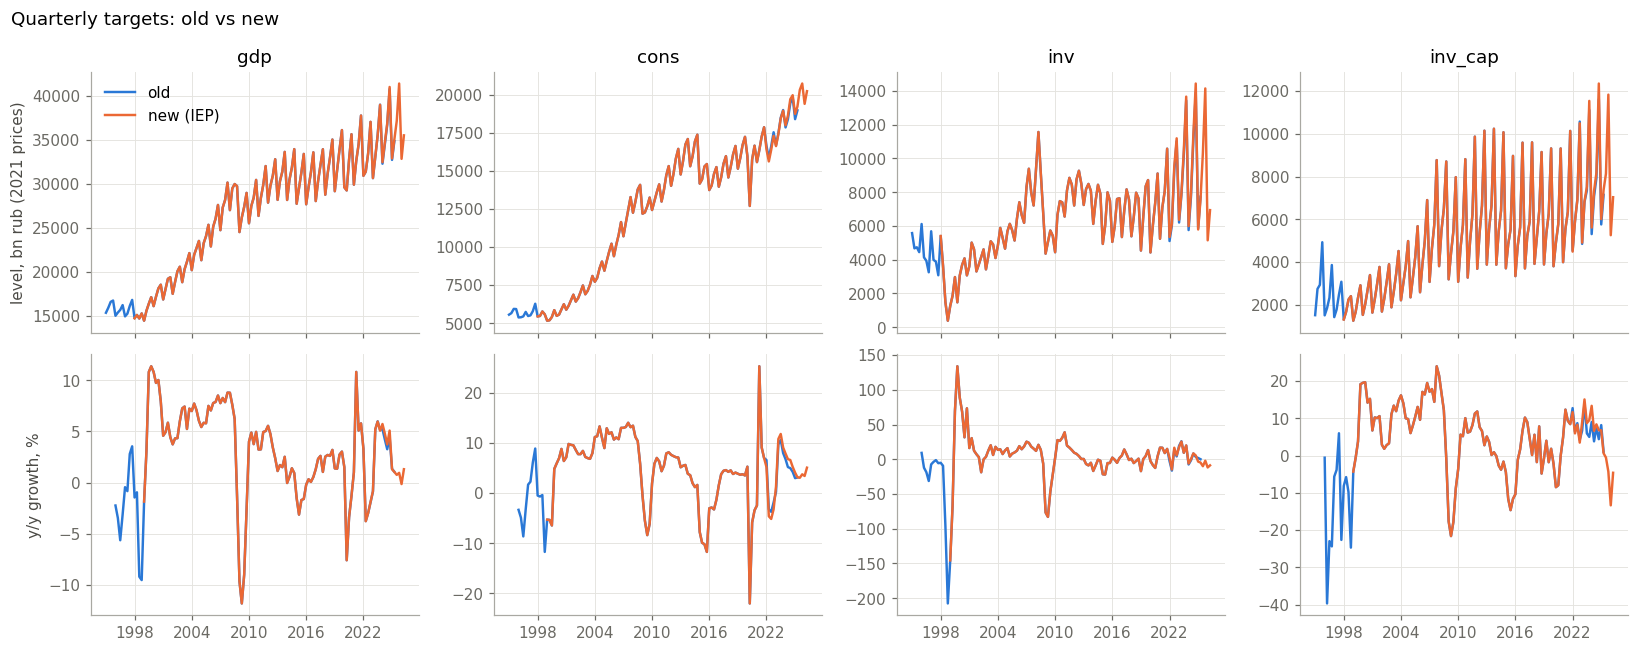

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex=True)
for i, col in enumerate(["gdp", "cons", "inv", "inv_cap"]):
    for frame, color, label in ((old_q, OLD_COLOR, "old"), (new_q, NEW_COLOR, "new (IEP)")):
        s = frame.select("date", col).sort("date")
        axes[0, i].plot(s["date"], s[col], color=color, label=label)
        g = yoy_growth(frame, col, 4)
        axes[1, i].plot(g["date"], g[col], color=color, label=label)
    axes[0, i].set_title(col)
    axes[1, i].xaxis.set_major_locator(mdates.YearLocator(6))
axes[0, 0].set_ylabel("level, bn rub (2021 prices)")
axes[1, 0].set_ylabel("y/y growth, %")
axes[0, 0].legend(frameon=False)
fig.suptitle("Quarterly targets: old vs new", x=0.01, ha="left")
fig.tight_layout()

## 6. Monthly variables - y/y growth, %, old (blue) vs new (orange)

Sorted from the least to the most similar. Where the lines coincide only orange is visible.

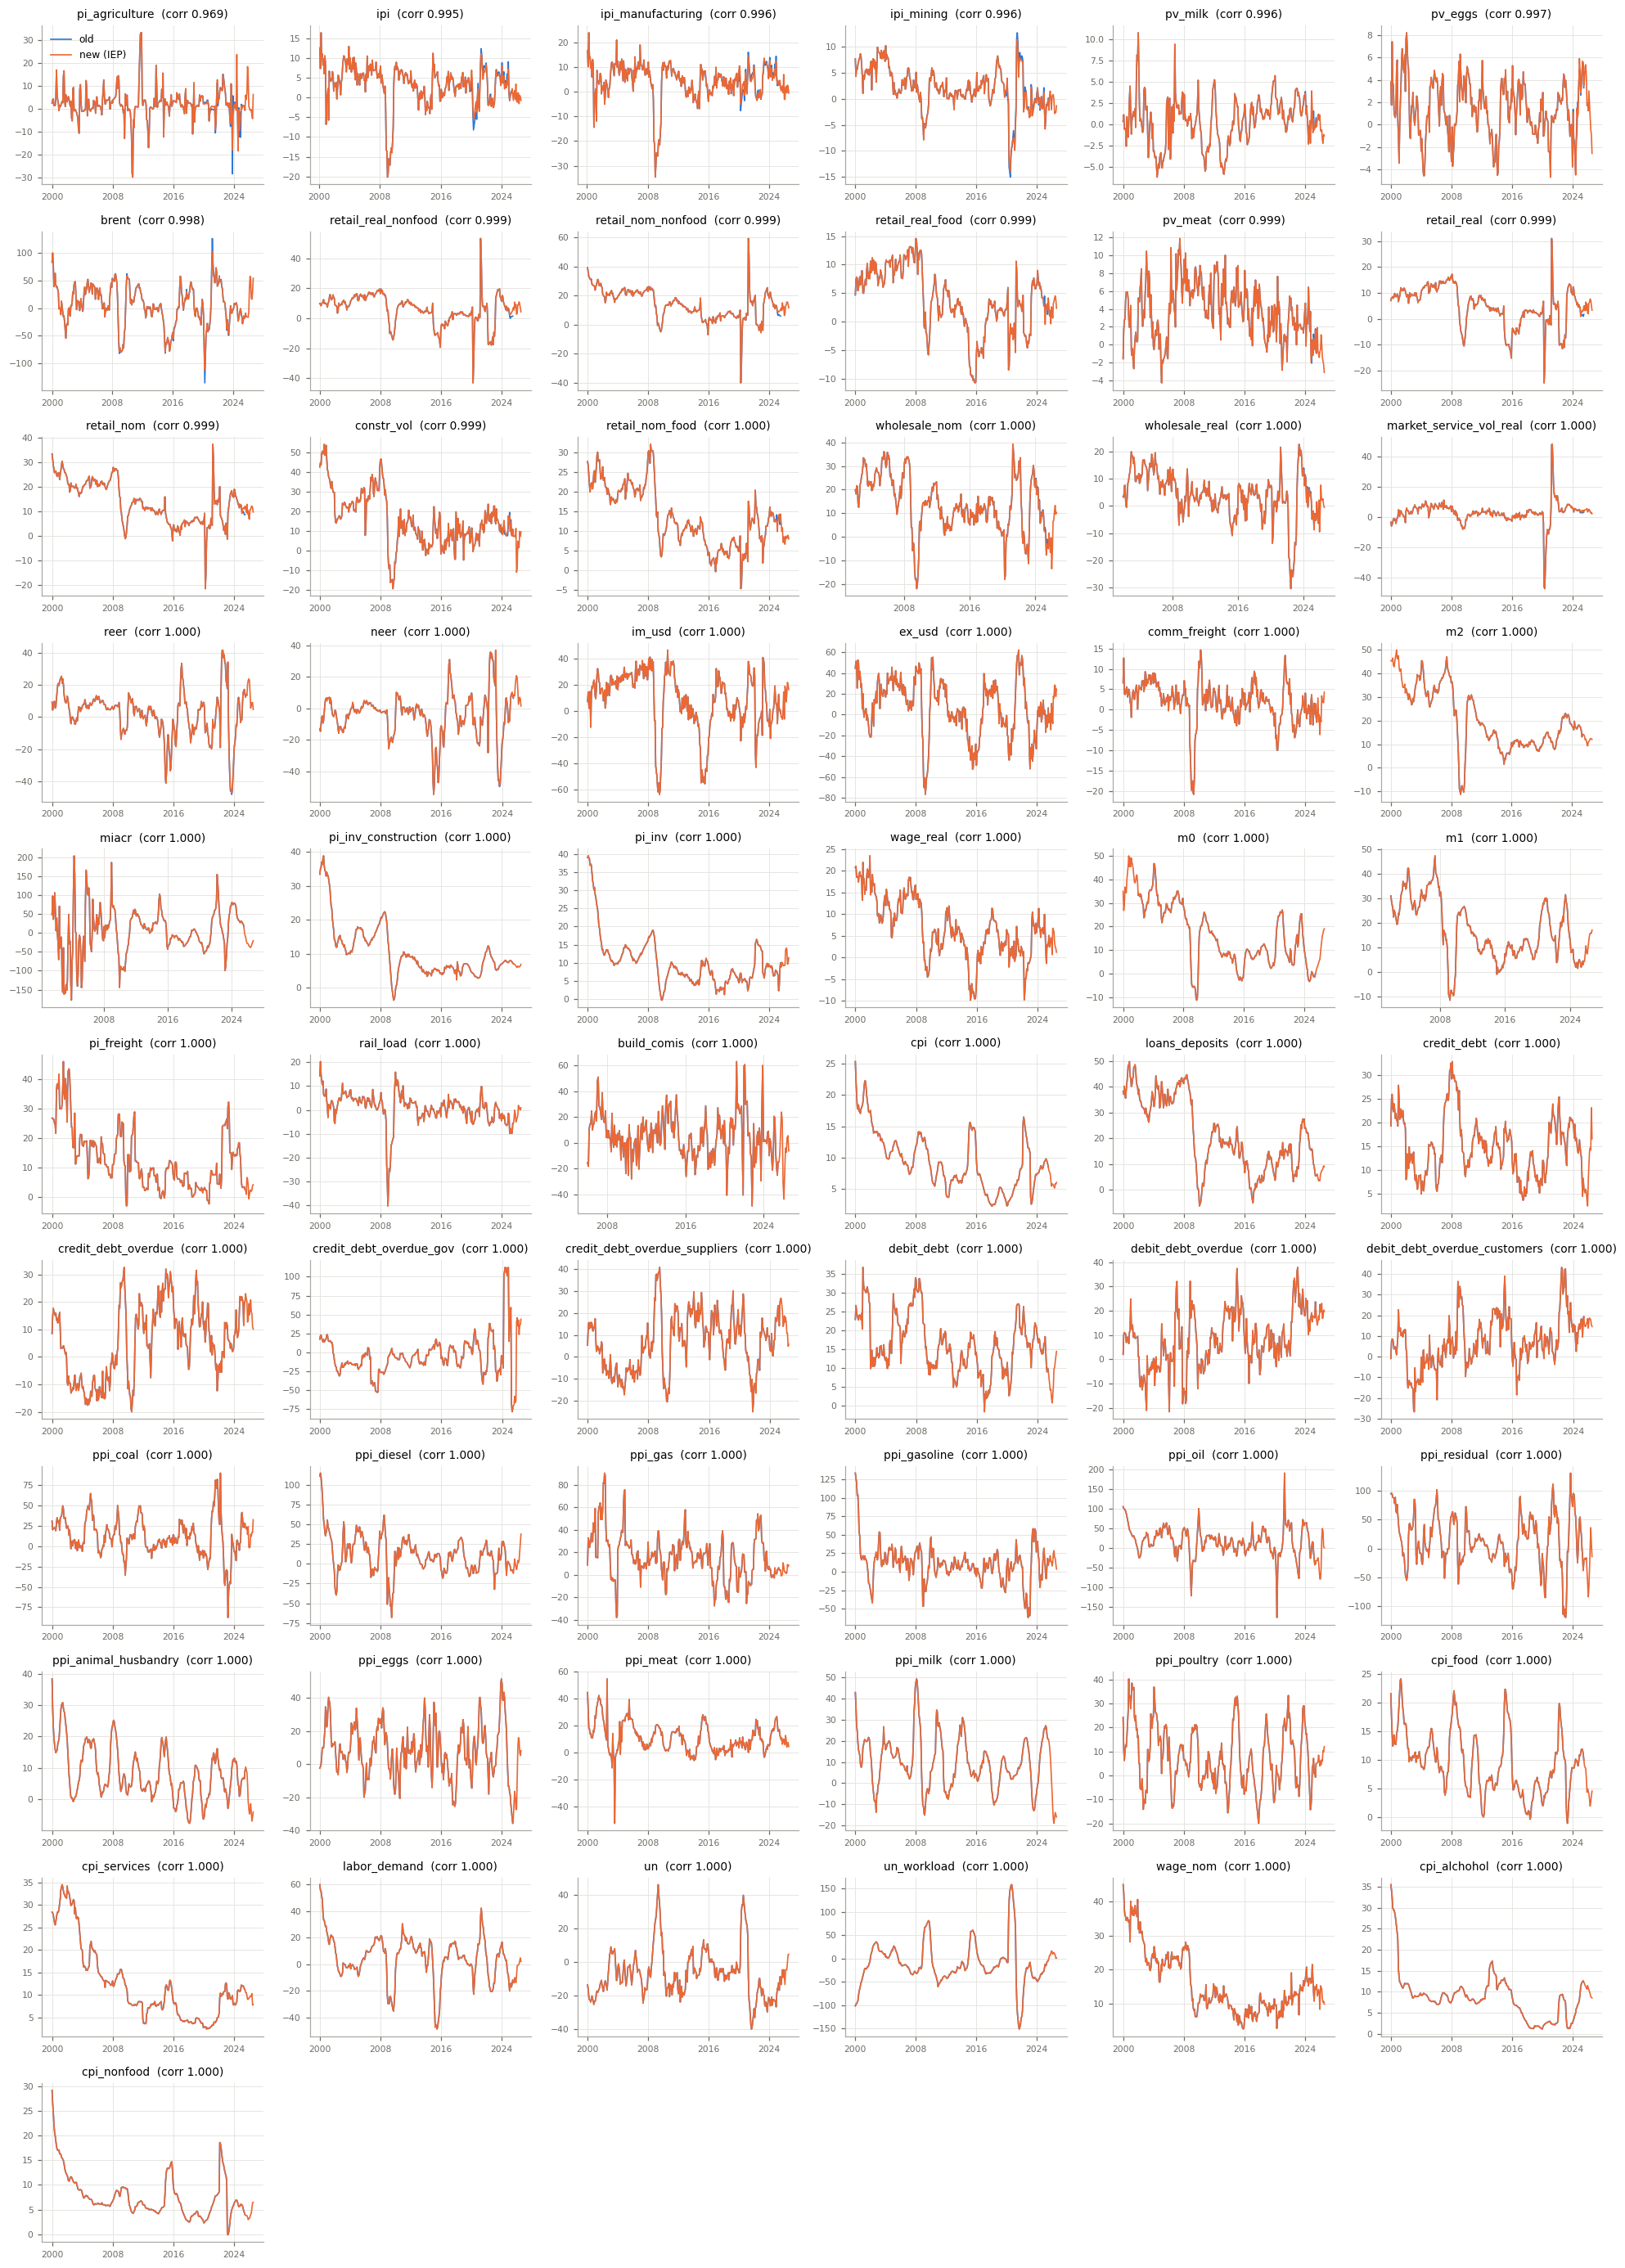

In [8]:
monthly_vars = cmp_m["var"].to_list()
n_cols = 6
n_rows = -(-len(monthly_vars) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 2.3 * n_rows))
for ax, col in zip(axes.flat, monthly_vars):
    g_old = yoy_growth(old_m, col, 12)
    g_new = yoy_growth(new_m, col, 12)
    ax.plot(g_old["date"], g_old[col], color=OLD_COLOR, linewidth=1.1, label="old")
    ax.plot(g_new["date"], g_new[col], color=NEW_COLOR, linewidth=1.1, label="new (IEP)")
    corr = cmp_m.filter(pl.col("var") == col)["corr_growth"].item()
    ax.set_title(f"{col}  (corr {corr:.3f})", fontsize=9)
    ax.tick_params(labelsize=7)
    ax.xaxis.set_major_locator(mdates.YearLocator(8))
for ax in list(axes.flat)[len(monthly_vars):]:
    ax.remove()
axes.flat[0].legend(frameon=False, fontsize=8)
fig.tight_layout()

## 7. Daily MIACR and its monthly average

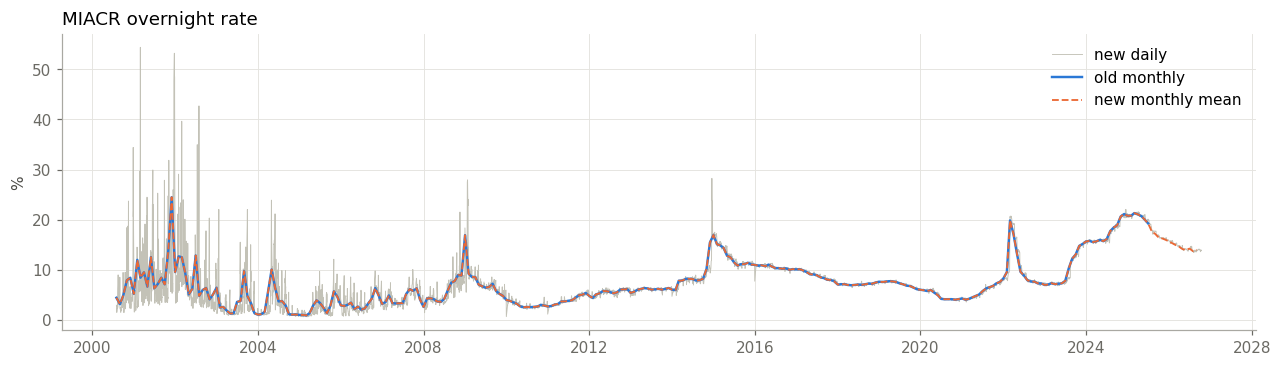

In [9]:
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(new_d["date"], new_d["miacr"], color="#c3c2b7", linewidth=0.6, label="new daily")
ax.plot(old_m["date"], old_m["miacr"], color=OLD_COLOR, label="old monthly")
ax.plot(new_m["date"], new_m["miacr"], color=NEW_COLOR, linewidth=1.2, linestyle="--", label="new monthly mean")
ax.set_ylabel("%")
ax.legend(frameon=False)
ax.set_title("MIACR overnight rate", loc="left");

## 8. Fixed bug of the old pipeline: y/y series chained as m/m

`chain_indeces` in `eng_ru_names_dict.py` contains `pi_agriculture` and `wholesale_real`, but their
raw values are % to the same month of the previous year. `_convert_indeces_to_basics` multiplies
them month after month, so the old index (and its `log_d12` feature) has little to do with the
published numbers. Both pipelines now chain them over 12 months (`yoy_indeces` in
`eng_ru_names_dict.py`, `chain_yoy` in data_iep), so the y/y change of the index equals the
published rate. The check below compares the legacy and the fixed transformation of the excel data.
Note: `preds/` and `preds/metrics.csv` were produced before the fix. (`wage_real` is labelled y/y in `eng_ru_names_dict`, but its
raw data in the excel file is actually m/m, so it was handled correctly.)

In [10]:
legacy = fs._convert_indeces_to_basics(giga_raw.rename({"date": "datem"}), chain_indeces + yoy_indeces).rename({"datem": "date"})
for col in yoy_indeces:
    check = (
        giga_raw.select("date", pl.col(col).alias("published_yoy"))
        .join(old_m.select("date", pl.col(col).alias("new")), on="date")
        .join(legacy.select("date", pl.col(col).alias("old")), on="date")
        .sort("date")
        .with_columns(
            new_index_yoy=pl.col("new") / pl.col("new").shift(12) * 100,
            old_index_yoy=pl.col("old") / pl.col("old").shift(12) * 100,
        )
        .drop_nulls()
    )
    print(
        f"{col:15s} corr(published y/y, FIXED index y/y) = {check.select(pl.corr('published_yoy', 'new_index_yoy')).item():.3f}   "
        f"corr(published y/y, LEGACY index y/y) = {check.select(pl.corr('published_yoy', 'old_index_yoy')).item():.3f}"
    )

pi_agriculture  corr(published y/y, FIXED index y/y) = 1.000   corr(published y/y, LEGACY index y/y) = 0.298
wholesale_real  corr(published y/y, FIXED index y/y) = 1.000   corr(published y/y, LEGACY index y/y) = 0.560


## 9. Similarity summary

In [11]:
summary = pl.concat([cmp_q.with_columns(freq=pl.lit("Q")), cmp_m.with_columns(freq=pl.lit("M"))]).with_columns(
    group=pl.when(pl.col("corr_growth") >= 0.999).then(pl.lit("1. identical (corr >= 0.999)"))
    .when(pl.col("corr_growth") >= 0.99).then(pl.lit("2. near-identical (0.99 - 0.999)"))
    .when(pl.col("corr_growth") >= 0.95).then(pl.lit("3. close (0.95 - 0.99)"))
    .otherwise(pl.lit("4. different (< 0.95)"))
)
print(f"compared variables: {summary.height} (quarterly {cmp_q.height}, monthly {cmp_m.height})")
print(f"median corr of y/y growth: {summary['corr_growth'].median():.4f}")
print(f"median share of periods with equal growth (< 0.05 pp): {summary['share_equal_growth'].median():.1%}")
summary.group_by("group").agg(pl.len().alias("n_vars"), pl.col("var")).sort("group")

compared variables: 65 (quarterly 4, monthly 61)
median corr of y/y growth: 1.0000
median share of periods with equal growth (< 0.05 pp): 100.0%


group,n_vars,var
str,u32,list[str]
"""1. identical (corr >= 0.999)""",56,"[""inv"", ""gdp"", … ""cpi_nonfood""]"
"""2. near-identical (0.99 - 0.999)""",8,"[""inv_cap"", ""cons"", … ""brent""]"
"""3. close (0.95 - 0.99)""",1,"[""pi_agriculture""]"


## 10. Conclusion

**The automatically collected IEP data reproduces the hand-collected data.** All 65 variables
present in both sets (4 quarterly + 61 monthly) agree in y/y growth with correlation ≥ 0.95:

* **56 variables are identical** (corr ≥ 0.999): GDP and gross accumulation, all prices (CPI and
  components, producer prices, investment and freight price indices), money (M0, M1, M2, MIACR), debts
  and loans, wages, labour market, foreign trade, exchange rates, retail and wholesale trade.
  For most of them the values are equal to the last digit.
* **8 are near-identical** (0.99 - 0.999): `cons`, `inv_cap`, industrial production (`ipi`,
  `ipi_mining`, `ipi_manufacturing`), `pv_milk`, `pv_eggs` and `brent`. The differences are
  Rosstat revisions in the newer release (IEP holds the latest vintage, the excel files a 2025 snapshot);
  Brent comes from the World Bank instead of FRED (same monthly average, small rounding differences).
* **1 is close** (0.969): `pi_agriculture`, again revisions of the published y/y rates
  (79% of the months are equal).

GDP components are chained into 2021 prices exactly like the «Сцепка» sheet: for 1998-2010 they are
equal to the old file to the digit, after 2011 they differ only by revisions (≤ 0.6% in levels).

**Differences to keep in mind**

1. `ipi_water_electro_gas` and `wage_debt_overdue` are not collected (IEP history starts only in 2014 / 2013),
   so the IEP feature set has 61 instead of 63 monthly variables.
2. Quarterly data starts in 1998 instead of 1995 (no earlier constant-price data on IEP); the models start in 2001, so nothing is lost.
3. The old pipeline treated `pi_agriculture` and `wholesale_real` (y/y rates) as m/m changes, which
   gave wrong features. Fixed in both pipelines; results in `preds/` still come from the buggy version.
4. The new data runs about a year further (to 2026 Q2 / 2026-09) and is refreshed with one command:
   `python -m data_iep.pipeline`.

**Bottom line:** the old excel files can be replaced by the IEP pipeline (`DATA_SOURCE = "iep"` in `config.py`)
with no loss of information for the models, apart from the two dropped variables.